In [1]:
import sys
import lightgbm as lgb
import sklearn

print("Python:", sys.executable)
print("LightGBM:", lgb.__version__)
print("scikit-learn:", sklearn.__version__)

Python: /Users/preeyapat/miniconda3/envs/homecredit/bin/python
LightGBM: 4.6.0
scikit-learn: 1.9.0


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
import joblib
import lightgbm as lgb

from lightgbm import LGBMClassifier

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    precision_score,
    recall_score,
    confusion_matrix,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

print("LightGBM:", lgb.__version__)

LightGBM: 4.6.0


In [3]:
ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_PATH = (
    ROOT / "data" / "processed" /
    "modeling_features.parquet"
)

assert DATA_PATH.exists(), "Parquet dataset not found"

con = duckdb.connect()

df = con.execute(
    "SELECT * FROM read_parquet(?)",
    [str(DATA_PATH)]
).df()

print("Dataset shape:", df.shape)
print("Positive rate:", round(df["TARGET"].mean() * 100, 2), "%")

display(df.head())

Dataset shape: (307511, 143)
Positive rate: 8.07 %


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,bureau_total_overdue,bureau_max_credit,bureau_max_days_overdue,bureau_accounts_currently_overdue,bureau_avg_days_since_credit,bureau_days_since_recent_credit,bureau_days_since_oldest_credit,bureau_debt_records_available,bureau_credit_records_available,bureau_debt_credit_ratio
0,117276,0,Cash loans,F,N,Y,2,180000.0,363190.5,26559.0,...,0.0,6201.0,0,0,142.000000,42,242,2,2,0.000000
1,117277,1,Cash loans,F,N,Y,1,337500.0,732915.0,79065.0,...,0.0,1057500.0,0,0,1197.583333,140,1607,10,12,0.049512
2,117278,0,Cash loans,M,Y,Y,0,117000.0,112500.0,11254.5,...,NaN,NaN,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,NaN
3,117279,0,Cash loans,F,N,N,3,157500.0,1125000.0,47794.5,...,NaN,NaN,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,NaN
4,117280,0,Cash loans,F,N,Y,0,135000.0,450000.0,23107.5,...,0.0,585000.0,0,0,1238.571429,303,2714,5,7,0.413792


In [4]:
numeric_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "credit_income_ratio",
    "annuity_income_ratio",
    "employment_years",
    "employment_sentinel_flag",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "has_bureau_history",
    "bureau_total_accounts",
    "bureau_active_accounts",
    "bureau_closed_accounts",
    "bureau_total_credit",
    "bureau_total_debt",
    "bureau_total_overdue",
    "bureau_max_days_overdue",
    "bureau_avg_days_since_credit",
    "bureau_debt_credit_ratio"
]

categorical_features = [
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_HOUSING_TYPE",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY"
]

features = numeric_features + categorical_features

assert all(col in df.columns for col in features)
assert df["SK_ID_CURR"].is_unique

X = df[features].copy()
y = df["TARGET"].astype(int)

X[numeric_features] = X[numeric_features].replace(
    [np.inf, -np.inf], np.nan
)

print("Number of features:", X.shape[1])
print("Target distribution:")
print(y.value_counts(normalize=True))

Number of features: 27
Target distribution:
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


In [5]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (184506, 27)
Validation: (61502, 27)
Test: (61503, 27)


In [6]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    sparse_threshold=1.0
)

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)

Training shape: (184506, 61)
Validation shape: (61502, 61)


In [7]:
lgbm_model = LGBMClassifier(
    objective="binary",
    metric="auc",
    n_estimators=800,
    learning_rate=0.04,
    num_leaves=15,
    max_depth=-1,
    min_child_samples=80,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=1,
    reg_lambda=2.0,
    random_state=42,
    n_jobs=4,
    verbosity=-1
)

lgbm_model.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_val_processed, y_val)],
    eval_metric="auc",
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=50,
            first_metric_only=True,
            verbose=True
        ),
        lgb.log_evaluation(period=100)
    ]
)

print("Best iteration:", lgbm_model.best_iteration_)

Training until validation scores don't improve for 50 rounds
[100]	valid_0's auc: 0.747795
[200]	valid_0's auc: 0.751842
[300]	valid_0's auc: 0.752965
[400]	valid_0's auc: 0.753688
[500]	valid_0's auc: 0.754015
Early stopping, best iteration is:
[524]	valid_0's auc: 0.754074
Evaluated only: auc
Best iteration: 524


In [8]:
from sklearn.base import clone

logistic_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        solver="liblinear",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

logistic_prob = logistic_model.predict_proba(X_val)[:, 1]

lgbm_prob = lgbm_model.predict_proba(
    X_val_processed
)[:, 1]

print("Logistic predictions:", len(logistic_prob))
print("LightGBM predictions:", len(lgbm_prob))

/Users/preeyapat/miniconda3/envs/homecredit/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Logistic predictions: 61502
LightGBM predictions: 61502


In [9]:
def evaluate_model(y_true, probabilities, threshold=0.10):
    predictions = (probabilities >= threshold).astype(int)

    return {
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Average Precision": average_precision_score(
            y_true, probabilities
        ),
        "Brier Score": brier_score_loss(
            y_true, probabilities
        ),
        "Precision @ 0.10": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall @ 0.10": recall_score(
            y_true, predictions, zero_division=0
        ),
        "Flagged @ 0.10": int(predictions.sum())
    }


comparison = pd.DataFrame({
    "Logistic Regression": evaluate_model(
        y_val, logistic_prob
    ),
    "LightGBM": evaluate_model(
        y_val, lgbm_prob
    )
}).T

display(comparison.round(4))

,ROC-AUC,Average Precision,Brier Score,Precision @ 0.10,Recall @ 0.10,Flagged @ 0.10
Logistic Regression,0.7441,0.2208,0.0688,0.1801,0.6008,16566.0
LightGBM,0.7541,0.2373,0.0681,0.1877,0.5954,15745.0


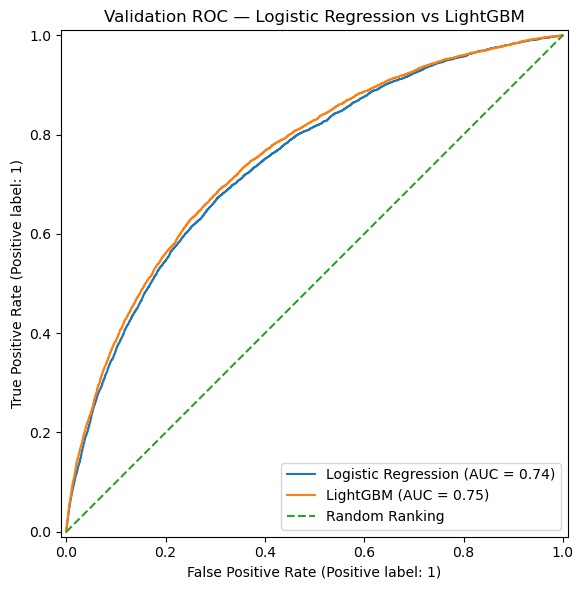

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_val,
    logistic_prob,
    name="Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_val,
    lgbm_prob,
    name="LightGBM",
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random Ranking"
)

ax.set_title("Validation ROC — Logistic Regression vs LightGBM")
ax.legend()

plt.tight_layout()
plt.show()

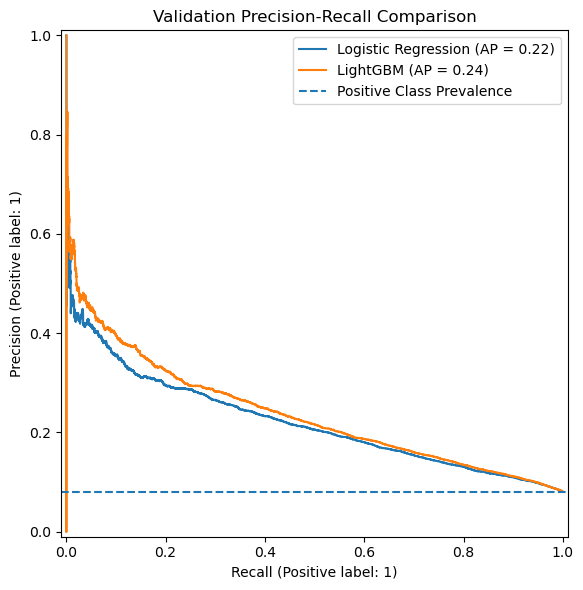

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))

PrecisionRecallDisplay.from_predictions(
    y_val,
    logistic_prob,
    name="Logistic Regression",
    ax=ax
)

PrecisionRecallDisplay.from_predictions(
    y_val,
    lgbm_prob,
    name="LightGBM",
    ax=ax
)

ax.axhline(
    y_val.mean(),
    linestyle="--",
    label="Positive Class Prevalence"
)

ax.set_title("Validation Precision-Recall Comparison")
ax.legend()

plt.tight_layout()
plt.show()

In [12]:
threshold_rows = []

for model_name, probabilities in [
    ("Logistic Regression", logistic_prob),
    ("LightGBM", lgbm_prob)
]:
    for threshold in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]:

        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        ).ravel()

        threshold_rows.append({
            "Model": model_name,
            "Threshold": threshold,
            "Flagged": int(predictions.sum()),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "False Positives": int(fp),
            "False Negatives": int(fn)
        })

threshold_comparison = pd.DataFrame(threshold_rows)

display(threshold_comparison.round(3))

,Model,Threshold,Flagged,Precision,Recall,False Positives,False Negatives
0,Logistic Regression,0.05,35069,0.120,0.844,30877,773
1,Logistic Regression,0.10,16566,0.180,0.601,13583,1982
2,Logistic Regression,0.15,8365,0.234,0.395,6404,3004
3,Logistic Regression,0.20,4424,0.285,0.254,3163,3704
4,Logistic Regression,0.30,1221,0.366,0.090,774,4518
5,Logistic Regression,0.50,63,0.524,0.007,30,4932
6,LightGBM,0.05,32797,0.126,0.833,28661,829
7,LightGBM,0.10,15745,0.188,0.595,12789,2009
8,LightGBM,0.15,8590,0.242,0.419,6508,2883
9,LightGBM,0.20,4982,0.288,0.289,3547,3530


In [13]:
def evaluate_top_fraction(y_true, probabilities, fraction=0.10):
    y_array = np.asarray(y_true)
    p_array = np.asarray(probabilities)

    k = int(np.ceil(len(y_array) * fraction))

    selected = np.argsort(-p_array, kind="stable")[:k]

    true_positives = y_array[selected].sum()

    return {
        "Flagged": k,
        "Precision@K": true_positives / k,
        "Recall@K": true_positives / y_array.sum()
    }

top_k_results = pd.DataFrame({
    "Logistic Regression": evaluate_top_fraction(
        y_val, logistic_prob
    ),
    "LightGBM": evaluate_top_fraction(
        y_val, lgbm_prob
    )
}).T

display(top_k_results.round(4))

,Flagged,Precision@K,Recall@K
Logistic Regression,6151.0,0.2578,0.3194
LightGBM,6151.0,0.2713,0.3362


,Feature,Importance
10,num__EXT_SOURCE_2,617
1,num__AMT_CREDIT,590
2,num__AMT_ANNUITY,578
11,num__EXT_SOURCE_3,568
7,num__employment_years,514
9,num__EXT_SOURCE_1,487
20,num__bureau_avg_days_since_credit,459
16,num__bureau_total_credit,425
6,num__annuity_income_ratio,381
5,num__credit_income_ratio,374


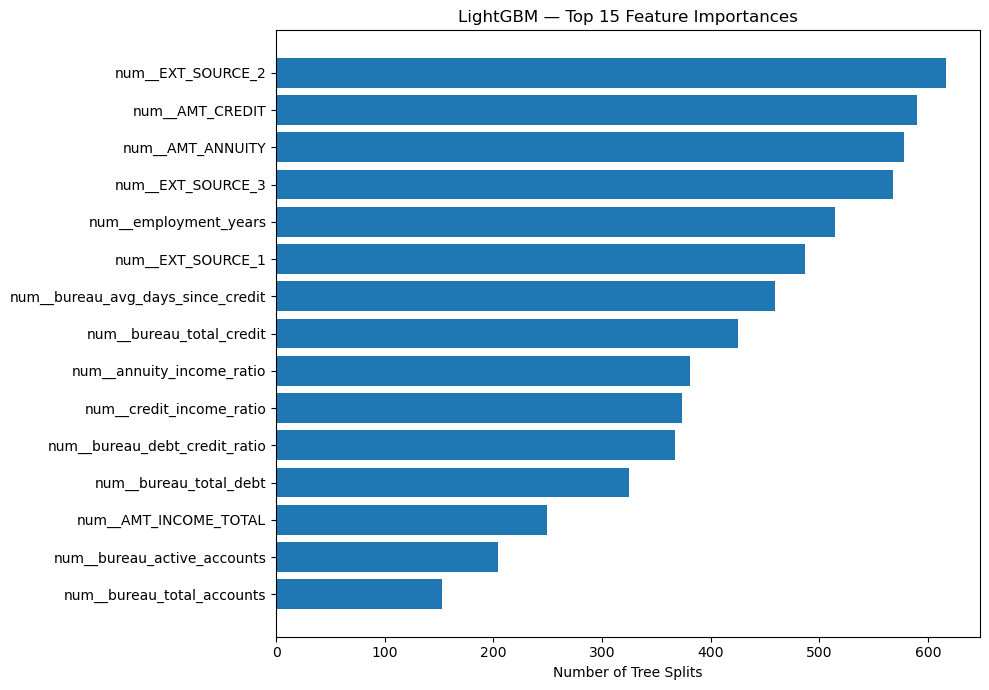

In [14]:
feature_names = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": lgbm_model.feature_importances_
})

importance = importance.sort_values(
    "Importance", ascending=False
)

display(importance.head(20))

top_features = importance.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_features["Feature"],
    top_features["Importance"]
)

ax.set_title("LightGBM — Top 15 Feature Importances")
ax.set_xlabel("Number of Tree Splits")

plt.tight_layout()
plt.show()

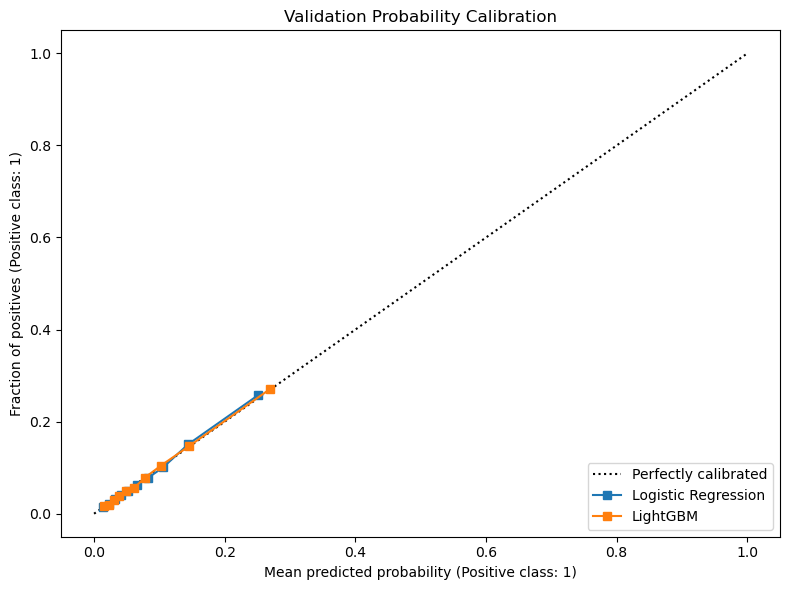

In [15]:
from sklearn.calibration import CalibrationDisplay

fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(
    y_val,
    logistic_prob,
    n_bins=10,
    strategy="quantile",
    name="Logistic Regression",
    ax=ax
)

CalibrationDisplay.from_predictions(
    y_val,
    lgbm_prob,
    n_bins=10,
    strategy="quantile",
    name="LightGBM",
    ax=ax
)

ax.set_title("Validation Probability Calibration")

plt.tight_layout()
plt.show()

In [16]:
MODEL_DIR = ROOT / "models"
REPORT_DIR = ROOT / "reports"

MODEL_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)

joblib.dump(
    {
        "preprocessor": preprocessor,
        "model": lgbm_model,
        "features": features
    },
    MODEL_DIR / "lightgbm_model.joblib"
)

comparison.to_csv(
    REPORT_DIR / "day06_model_comparison.csv"
)

threshold_comparison.to_csv(
    REPORT_DIR / "day06_threshold_comparison.csv",
    index=False
)

top_k_results.to_csv(
    REPORT_DIR / "day06_top_k_results.csv"
)

importance.to_csv(
    REPORT_DIR / "day06_feature_importance.csv",
    index=False
)

print("Day 6 results saved successfully.")

Day 6 results saved successfully.
